### Top Rows

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

file_path = "results-filtered-dataset.csv"
df = pd.read_csv(file_path)



## Experiment Summary
### Filtered rows: **1316**
- v0 faster: **844**
- v5 faster: **472**


## v0 Wins

,dataset,k,v0_min,v5_min,ratio
3109,Sieber,5,3.515022,682.6322,194.204247
4019,TSOPF_RS_b2383_c1,4,14.614610,1800.0000,123.164422
533,bmwcra_1,10,22.538936,1800.0000,79.861800
1850,karted,15,22.569116,1800.0000,79.755007
4282,wikipedia_link_sr,8,18.431310,1000.0876,54.260256
...,...,...,...,...,...
1420,G2,20,1.145652,2.3011,2.008551
2747,pwtk,15,3.824272,7.6679,2.005061
377,barrier2-4,5,1.106459,2.2166,2.003328
4142,web-uk-2005,15,1.037030,2.0766,2.002449


## v5 Wins

,dataset,k,v0_min,v5_min,ratio
3996,TSOPF_RS_b162_c1,20,1800.000000,1.2078,1490.312966
3995,TSOPF_RS_b162_c1,10,1800.000000,1.2389,1452.901768
2628,pkustk09,20,1800.000000,1.3788,1305.483029
3999,TSOPF_RS_b162_c3,20,1800.000000,1.5517,1160.018045
3998,TSOPF_RS_b162_c3,10,1800.000000,1.5911,1131.292816
...,...,...,...,...,...
1963,livejournal-groupmemberships,8,448.905652,219.2490,2.047470
1061,edit-eswiki,10,3.865942,1.8891,2.046446
755,conf6_0-8x8-30,20,2.855615,1.4046,2.033045
4298,wiki-Talk,8,50.332650,24.9891,2.014184


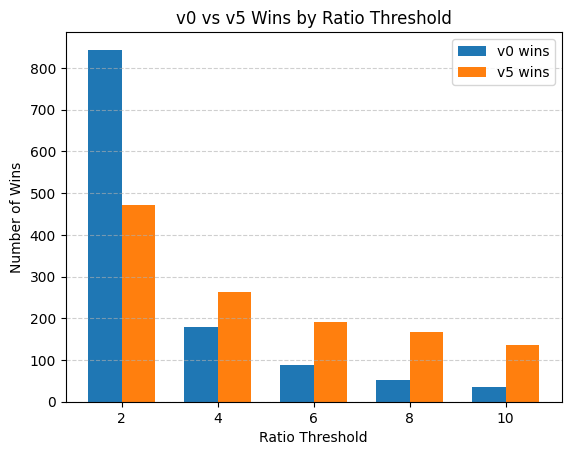

In [2]:
from IPython.display import display, Markdown
import numpy as np
import pandas as pd

group1 = 'v0'
group2 = 'v5'
branchings = 'S R P'

group1_alg = [f"{group1}-{br}" for br in branchings.split()]
group2_alg = [f"{group2}-{br}" for br in branchings.split()]

all_algos = group1_alg + group2_alg

# Ensure only existing columns are used
valid_cols = [c for c in all_algos if c in df.columns]

df[valid_cols] = (
    df[valid_cols]
    .replace("x", 1800)
    .apply(pd.to_numeric, errors="coerce")
)

df[f"{group1}_min"] = df[group1_alg].min(axis=1)
df[f"{group2}_min"] = df[group2_alg].min(axis=1)

# avoid divide-by-zero
df["ratio"] = (
    np.maximum(df[f"{group1}_min"], df[f"{group2}_min"])
    / np.maximum(np.minimum(df[f"{group1}_min"], df[f"{group2}_min"]), 1e-9)
)

filtered_rows = df[
    (df[f"{group1}_min"] > 1) &
    (df[f"{group2}_min"] > 1) &
    (df["ratio"] >= 2)
].sort_values(by="ratio", ascending=False).copy()

# Split into two tables
group1_wins_table = filtered_rows[
    filtered_rows[f"{group1}_min"] < filtered_rows[f"{group2}_min"]
]

group2_wins_table = filtered_rows[
    filtered_rows[f"{group2}_min"] < filtered_rows[f"{group1}_min"]
]

total = len(filtered_rows)

display(Markdown(f"""
## Experiment Summary
### Filtered rows: **{total}**
- {group1} faster: **{len(group1_wins_table)}**
- {group2} faster: **{len(group2_wins_table)}**
"""))

display(Markdown(f"## {group1} Wins"))
display(group1_wins_table[["dataset", "k", f"{group1}_min", f"{group2}_min", "ratio"]])

display(Markdown(f"## {group2} Wins"))
display(group2_wins_table[["dataset", "k", f"{group1}_min", f"{group2}_min", "ratio"]])

ratio_thresholds = [2, 4, 6, 8, 10]

group1_wins_list = []
group2_wins_list = []

den = np.minimum(df[f"{group1}_min"], df[f"{group2}_min"])
df["ratio"] = np.maximum(df[f"{group1}_min"], df[f"{group2}_min"]) / den.replace(0, np.nan)

for r in ratio_thresholds:
    filtered_rows = df[
        (df[f"{group1}_min"] > 1) &
        (df[f"{group2}_min"] > 1) &
        (df["ratio"] >= r)
    ]

    total = len(filtered_rows)

    group1_wins = (filtered_rows[f"{group1}_min"] < filtered_rows[f"{group2}_min"]).sum()
    group2_wins = total - group1_wins

    group1_wins_list.append(group1_wins)
    group2_wins_list.append(group2_wins)

# Plot
x = np.arange(len(ratio_thresholds))
width = 0.35

plt.figure()

plt.bar(x - width/2, group1_wins_list, width, label=f"{group1} wins")
plt.bar(x + width/2, group2_wins_list, width, label=f"{group2} wins")

plt.xticks(x, [f"{r}" for r in ratio_thresholds])
plt.xlabel("Ratio Threshold")
plt.ylabel("Number of Wins")
plt.title(f"{group1} vs {group2} Wins by Ratio Threshold")

plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.show()

### Varying Ratio Threshold

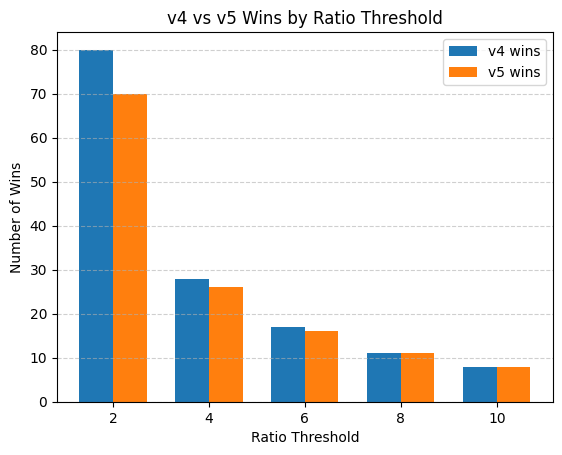

In [109]:
ratio_thresholds = [2, 4, 6, 8, 10]

group1_wins_list = []
group2_wins_list = []

den = np.minimum(df[f"{group1}_min"], df[f"{group2}_min"])
df["ratio"] = np.maximum(df[f"{group1}_min"], df[f"{group2}_min"]) / den.replace(0, np.nan)

for r in ratio_thresholds:
    filtered_rows = df[
        (df[f"{group1}_min"] > 1) &
        (df[f"{group2}_min"] > 1) &
        (df["ratio"] >= r)
    ]

    total = len(filtered_rows)

    group1_wins = (filtered_rows[f"{group1}_min"] < filtered_rows[f"{group2}_min"]).sum()
    group2_wins = total - group1_wins

    group1_wins_list.append(group1_wins)
    group2_wins_list.append(group2_wins)

# Plot
x = np.arange(len(ratio_thresholds))
width = 0.35

plt.figure()

plt.bar(x - width/2, group1_wins_list, width, label=f"{group1} wins")
plt.bar(x + width/2, group2_wins_list, width, label=f"{group2} wins")

plt.xticks(x, [f"{r}" for r in ratio_thresholds])
plt.xlabel("Ratio Threshold")
plt.ylabel("Number of Wins")
plt.title(f"{group1} vs {group2} Wins by Ratio Threshold")

plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.show()